# ACCESS-OM3 and ACCESS-OM2 horizontal mean temperature and salinity Hovmollers: drift from initial condition, vs depth and time

Related issue: https://github.com/ACCESS-Community-Hub/access-om3-25km-paper-1/issues/8

Run with a lot of cores (say, 28).

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"
# esm_file = '/scratch/x77/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test5-38867fcd/datastore.json'
# esm_file = '/scratch/x77/aek156/access-om3/archive/MC_25km_era_iaf+wombatlite-test5-era-8a51ed1d/datastore.json'
# esm_file = '/scratch/x77/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test-test5-tweaks-dd8d35ed/datastore.json'
#esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/tm70/cyb561/esm_datastores/ol01_full/MC_8km_jra_ryf-test2-expt-c349f800/datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/"
nbname = "temp-salt-vs-depth-time.ipynb"


In [3]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from exptdata_access import guess_experiment_from_esm_file
# Infer model information from the datastore path
expt_key, info = guess_experiment_from_esm_file(esm_file)
model_name = info["model"]             # OM3 or CM3
print(f"Running notebook for model: {model_name}")
print("ESM datastore path:", esm_file)

Running notebook for model: ACCESS-OM3
ESM datastore path: /g/data/tm70/cyb561/esm_datastores/ol01_full/MC_8km_jra_ryf-test2-expt-c349f800/datastore.json


In [4]:
IAF = esm_file.find('iaf') > 0
IAF

False

In [5]:
import os
import numpy as np
import xarray as xr
import cftime
import cf_xarray as cfxr
import cf_xarray.units
import pint_xarray
from pint import application_registry as ureg
import intake
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib as mpl
from distributed import Client
import cmocean as cm
import cartopy.crs as ccrs
import cartopy.feature as cft
from shapely import geometry
from textwrap import wrap
from tqdm.notebook import tqdm
xr.set_options(keep_attrs=True);  # cf_xarray works best when xarray keeps attributes by default

In [6]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [7]:
from model_agnostic import patch_broken_conda_env, patch_dask_workers
patch_broken_conda_env()   # no-op on healthy conda envs
client = Client(threads_per_worker=1)
patch_dask_workers(client) # patch the dask workers too
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 16
Total threads: 16,Total memory: 188.56 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:38709,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:33965,Total threads: 1
Dashboard: http://127.0.0.1:33299/status,Memory: 11.78 GiB
Nanny: tcp://127.0.0.1:33125,


## Define regions

Text(0.5, 1.0, 'Regions (BUG: incorrect shapes north of 65°N)')

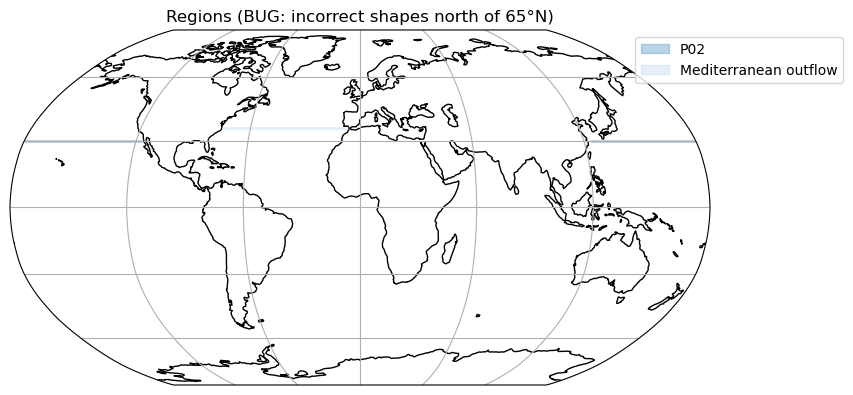

In [8]:
regions = { # [minx, maxx, miny, maxy], using model longitude range (-280 to 80)
    # "Global": [-280, 80, -90, 90],
    # "Arctic": [-280, 80, 65, 90],
    # "Southern Ocean": [-280, 80, -82, -63],
    # "ACC": [-280, 80, -63, -45],
    # "Southern Pacific": [-210, -70, -45, -20],
    # "Tropical Pacific": [-240, -100, -20, 20],
    # "North Pacific": [-240, -100, 20, 65],
    # "South Atlantic": [-60, 20, -45, -20],
    # "Tropical Atlantic": [-70, 20, -20, 20],
    #"North Atlantic": [-100, 0, 20, 65],
    # "Indian": [30, 120, -45, 20],
    # "Aegean Sea": [18, 27.5, 34, 44],
    #"Black Sea": [27.5, 43, 40.5, 48],
    # "Baltic Sea": [13, 30, 53, 58],
    # "Mediterranean Sea": [0, 35, 31, 41],
    # "Red Sea": [33, 44, 12, 29],
    # "Persian Gulf": [47, 56, 24, 31],
    # "White Sea": [31, 41, 63, 68],
# the following are from Transects.ioynb
    # 'SR3': [140-360, 140-360, -67, -42], # to match Kiss et al 2020
    # 'P16': [-150, -150, -76, 61], # to match Kiss et al 2020
    # 'A16': [-25, -25, -75.01, 65], # to match Kiss et al 2020
    # 'I08-09': [95-360, 95-360, -65, 15.1], # to match Kiss et al 2020
    'P02': [ -237, -117, 30, 30],
    # 'P04': [ -235, -85, 9.5, 9.5],
    # 'P06': [ -207, -72, -32.5, -32.5],
    # 'OSNAP': [-62, -5, 59, 59], # only roughly near OSNAP
    # 'A02': [-52, -5, 48, 48], # only roughly near A02
    # 'A05': [-96, -17, 24.5, 24.5],
    # 'A10': [-50, 17, -30, -30],
    'Mediterranean outflow': [-75, -6, 36, 36],
    # 'I05 west': [29, 80, -33, -33],
    # 'I05 east': [-280, -246, -33, -33],
}
regions = {k: dict(zip(["minx", "maxx", "miny", "maxy"], v)) for k, v in regions.items()}  # convert to dicts

for r, d in regions.items():
    for k, x in d.items():
        if k in ["minx", "maxx"] and x != max(-280, min(x, 80)):
            raise ValueError(f"{r} {k} = {x} is outside the range -280 to 80")

fig = plt.figure(figsize=(10, 4))

colors = mpl.color_sequences['tab20']
try:  # set Global color to white 
    colors[list(regions.keys()).index("Global")] = (1, 1, 1)
except ValueError:
    pass

ax = plt.axes(position=[0.05,0.05,0.7,0.9], projection=ccrs.Robinson())
ax.coastlines(resolution="110m")
ax.gridlines(draw_labels=False)

legend_elements = []
for i, (region, limits) in enumerate(regions.items()):
    ax.add_geometries([geometry.box(**limits)], crs=ccrs.PlateCarree(), color=colors[i], alpha=0.3)
    legend_elements.append(Patch(color=colors[i], alpha=0.3, label=region))

ax.legend(handles=legend_elements, bbox_to_anchor=(1.2, 1.00))
plt.title("Regions (BUG: incorrect shapes north of 65°N)")

## Load data from ACCESS-OM3

In [9]:
if model_name == "ACCESS-CM3":
    catalogs = [esm_file]
else:
    catalogs = [
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json',
                # '/g/data/ol01/access-om3-output/access-om3-025/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm1-d968c801/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm2-5dc49da6/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm3-da330542/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm4-9fd08880/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm5-9b5dbfa9/datastore.json',
                esm_file,
                # '/scratch/tm70/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test4-rerun-099ed2b5/datastore.json',
                # '/scratch/tm70/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test5test-67872f64/datastore.json',
                # '/scratch/x77/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test5-38867fcd/datastore.json',
                # '/scratch/x77/aek156/access-om3/archive/MC_25km_era_iaf+wombatlite-test5-era-8a51ed1d/datastore.json',
                # '/scratch/x77/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test-test5-tweaks-dd8d35ed/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-COARE-12fab415/datastore.json',
            ]
catalogs

['/g/data/tm70/cyb561/esm_datastores/ol01_full/MC_8km_jra_ryf-test2-expt-c349f800/datastore.json']

In [10]:
# helper for loading area
def get_area_var(ds, candidates=("areacello", "area_t")): 
    for v in candidates:
        sub = ds.search(variable=v)
        if len(sub.df):
            dvars = sub.to_dask()
            return dvars[list(dvars.data_vars)[0]]
    raise ValueError(f"No area variable found among {candidates}")

In [11]:
from exptdata_access import get_exptname_from_path
om3datastores = { get_exptname_from_path(c):
               intake.open_esm_datastore(c,
                                         columns_with_iterables=[
                                            "variable",
                                            "variable_long_name",
                                            "variable_standard_name",
                                            "variable_cell_methods",
                                            "variable_units"]
                                        )
              for c in catalogs }
om3datastores

{'MC_8km_jra_ryf-test2-expt-c349f800': <datastore catalog with 32 dataset(s) from 3843 asset(s)>}

In [12]:
om3varnames = [ 'thetao', 'so' ]

om3chunks = {"xh": -1, "yh": -1, "z_l": -1}  # remove "yh": -1 for resolution finer than 25km

if model_name == "ACCESS-CM3":
    om3chunks["time"] = 1  # CM3 stores yearly files; avoid ~6 GB chunks

om3vars = {
    vname: {expt: ds.search(variable=vname).to_dask(
                xarray_open_kwargs = dict(
                    chunks=om3chunks,
                    decode_timedelta=True
                )
            )[vname]
            for expt, ds in om3datastores.items()
          }
    for vname in om3varnames
    }

om3area = {expt: get_area_var(ds) for expt, ds in om3datastores.items()} # get area for weighting - NOT TESTED FOR CM3 YET

# omit latitudes with grid bug in this run https://github.com/ACCESS-NRI/ocean_model_grid_generator/issues/7
for vname, d in om3vars.items():
    try:
        d['25km-iaf-test-for-AK-expt-7df5ef4c'] = d['25km-iaf-test-for-AK-expt-7df5ef4c'].isel(yh=slice(10, None))
    except ValueError:
        d['25km-iaf-test-for-AK-expt-7df5ef4c'] = d['25km-iaf-test-for-AK-expt-7df5ef4c'].isel(yq=slice(10, None))
    except KeyError:
        pass
        
# same fix to area
try:
    om3area['25km-iaf-test-for-AK-expt-7df5ef4c'] = om3area['25km-iaf-test-for-AK-expt-7df5ef4c'].isel(yh=slice(10, None))
except (ValueError, KeyError):
    pass
    
if IAF:
    for vname, d in om3vars.items():
        for expt in d:
            try:
                d[expt] = d[expt].convert_calendar("proleptic_gregorian", use_cftime=True)
            except KeyError:
                pass

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:316: ConcatenationWarning: Attempting to concatenate datasets without valid dimension coordinates: retaining only first dataset. Request valid dimension coordinate to silence this warning.
  warnings.warn(


## Load data from ACCESS-OM2
use control - see https://forum.access-hive.org.au/t/access-om2-control-experiments/258#p-747-ryf-7

In [13]:
if model_name == "ACCESS-CM3":
    data_name = 'ACCESS-CM2'
    om2exptname = 'cj877'  # CM2 control archive on /g/data/p73 (same reference as pPV.ipynb)
else:
    data_name = 'ACCESS-OM2'
    if IAF:
        om2exptname = '025deg_jra55_iaf_omip2_cycle1'
    else:
        om2exptname = '025deg_jra55_ryf9091_gadi'  # monthly temp only for 1900-1903, and 2300-, with annual data in the gap
    om2datastores = {om2exptname: intake.cat.access_nri[om2exptname]}

In [14]:
om2varnames = [ 'temp', 'salt' ]

if model_name == "ACCESS-CM3":
    # Reference: ACCESS-CM2 cj877 control archive (same source as pPV.ipynb and
    # Overturning_in_ACCESS_OM3.ipynb). Limit to the last 600 months to match
    # the CM3 record length; each cj877 file holds 6 months.
    from pathlib import Path
    cm2_dir = Path("/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ocn")
    n_months = 600

    def _load_cm2(varname):
        files = sorted(cm2_dir.glob(f"ocean-3d-{varname}-1-monthly-mean-ym_*.nc"))
        if not files:
            raise FileNotFoundError(f"No cj877 monthly files found for {varname!r}")
        files = files[-((n_months + 5) // 6):]
        ds = xr.open_mfdataset(
            files,
            combine="by_coords",
            parallel=True,
            chunks={"time": 1, "xt_ocean": -1, "yt_ocean": -1, "st_ocean": -1},
            decode_timedelta=True,
            use_cftime=True,  # cj877 model years (~453-503) can't be datetime64
            data_vars="minimal", coords="minimal", compat="override",
        )
        return ds[varname]

    om2vars = { vname: {om2exptname: _load_cm2(vname)} for vname in om2varnames }

    # Relabel the CM2 control-run times onto the CM3 time axis so the panels can
    # share the x-axis (same approach as Overturning_in_ACCESS_OM3.ipynb) — this
    # also avoids mixing cftime and datetime64 axes, which matplotlib can't share.
    cm3_time = next(iter(om3vars[om3varnames[0]].values())).time
    for vname, dd in om2vars.items():
        for expt, da in dd.items():
            n = min(da.sizes["time"], cm3_time.sizes["time"])
            if da.sizes["time"] != cm3_time.sizes["time"]:
                print(f"Aligning {expt} {vname} with last {n} time steps")
            dd[expt] = (da.isel(time=slice(-n, None))
                          .assign_coords(time=("time", cm3_time.isel(time=slice(-n, None)).values)))

    grid_file = cm2_dir.parent / "ocean_grid.nc"  # MIGHT NEED TO UPDATE THIS
    om2area = {om2exptname: xr.open_dataset(grid_file)["area_t"]}  # get area for weighting - NOT TESTED

else:
    om2vars = {
        vname: {expt: ds.search(variable=vname, frequency="1mon").to_dask(
                    xarray_open_kwargs = dict(
                        chunks={"xt_ocean": -1, "yt_ocean": -1, "st_ocean" : -1},  # remove "yt_ocean": -1 for resolution finer than 25km
                        decode_timedelta=True
                    )
                )[vname]
                for expt, ds in om2datastores.items()
              }
        for vname in om2varnames
        }
    
    om2area = {om2exptname: get_area_var(om2datastores[om2exptname])} # get area for weighting
    
    if IAF:
        for vname, d in om2vars.items():
            for expt in d:
                try:
                    d[expt] = d[expt].convert_calendar("proleptic_gregorian", use_cftime=True)
                except KeyError:
                    pass

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

...

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: SerializationWarning: Unable to decode time axis in

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:316: ConcatenationWarning: Attempting to concatenate datasets without valid dimension coordinates: retaining only first dataset. Request valid dimension coordinate to silence this warning.
  warnings.warn(


# Calculate Hovmollers for each region - SLOW!

In [15]:
def area_weighted_mean(da, area, dims):
    """area weighted mean using xarray.DataArray.weighted"""
    wet = np.isfinite(da.isel(time=0)) if "time" in da.dims else np.isfinite(da) # wet mask
    weights = area.broadcast_like(wet).where(wet).fillna(0) # set land weights to 0
    return da.weighted(weights).mean(dim=dims) # weighted mean across specified dims

## OM3

In [16]:
%%time
om3vars_hov = dict()
for region, b in tqdm(regions.items(), desc='regions'):
    om3vars_hov[region] = dict()
    minx, maxx, miny, maxy = b.values()
    meandims = []
    if minx == maxx:
        xsel = minx
        xmethod = "nearest"
    else:
        xsel = slice(minx, maxx)
        xmethod = None
        meandims.append("xh")
    if miny == maxy:
        ysel = miny
        ymethod = "nearest"
    else:
        ysel = slice(miny, maxy)
        ymethod = None
        meandims.append("yh")
    for vname, vdatadict in tqdm(om3vars.items(), desc=f'   {region} variables'):
        om3vars_hov[region][vname] = dict()
        for expt, da in tqdm(vdatadict.items(), desc=f'      {vname} experiments', ):
            om3vars_hov[region][vname][expt] = area_weighted_mean(
                        da.sel(xh=xsel, method=xmethod).sel(yh=ysel, method=ymethod),
                        om3area[expt].sel(xh=xsel, method=xmethod).sel(yh=ysel, method=ymethod),
                        dims=meandims,
                      ).load()

regions:   0%|          | 0/2 [00:00<?, ?it/s]

   P02 variables:   0%|          | 0/2 [00:00<?, ?it/s]

      thetao experiments:   0%|          | 0/1 [00:00<?, ?it/s]

2026-10-23 11:26:55,907 - distributed.worker.memory - WARNING - Unmanaged memory use is high. This may indicate a memory leak or the memory may not be released to the OS; see https://distributed.dask.org/en/latest/worker-memory.html#memory-not-released-back-to-the-os for more information. -- Unmanaged memory: 8.26 GiB -- Worker memory limit: 11.78 GiB


2026-10-23 11:27:05,374 - distributed.worker.memory - WARNING - Unmanaged memory use is high. This may indicate a memory leak or the memory may not be released to the OS; see https://distributed.dask.org/en/latest/worker-memory.html#memory-not-released-back-to-the-os for more information. -- Unmanaged memory: 8.26 GiB -- Worker memory limit: 11.78 GiB


...

2026-10-23 12:33:00,951 - distributed.worker.memory - WARNING - Worker is at 37% memory usage. Resuming worker. Process memory: 4.45 GiB -- Worker memory limit: 11.78 GiB


2026-10-23 12:33:33,590 - distributed.worker.memory - WARNING - Unmanaged memory use is high. This may indicate a memory leak or the memory may not be released to the OS; see https://distributed.dask.org/en/latest/worker-memory.html#memory-not-released-back-to-the-os for more information. -- Unmanaged memory: 8.15 GiB -- Worker memory limit: 11.78 GiB


2026-10-23 12:34:25,585 - distributed.worker.memory - WARNING - Unmanaged memory use is high. This may indicate a memory leak or the memory may not be released to the OS; see https://distributed.dask.org/en/latest/worker-memory.html#memory-not-released-back-to-the-os for more information. -- Unmanaged memory: 8.33 GiB -- Worker memory limit: 11.78 GiB


2026-10-23 12:34:26,761 - distributed.worker.memory - WARNING - Unmanaged memory use is high. This may indicate a memory leak or the memory may not be released to the OS; see https://distributed.dask.org/en/latest/worker-memory.html#memory-not-released-back-to-the-os for more information. -- Unmanaged memory: 8.26 GiB -- Worker memory limit: 11.78 GiB


CPU times: user 12min 47s, sys: 9min 58s, total: 22min 45s
Wall time: 1h 14min 51s


## OM2

In [17]:
%%time
om2vars_hov = dict()
for region, b in tqdm(regions.items(), desc='regions'):
    om2vars_hov[region] = dict()
    minx, maxx, miny, maxy = b.values()
    meandims = []
    if minx == maxx:
        xsel = minx
        xmethod = "nearest"
    else:
        xsel = slice(minx, maxx)
        xmethod = None
        meandims.append("xt_ocean")
    if miny == maxy:
        ysel = miny
        ymethod = "nearest"
    else:
        ysel = slice(miny, maxy)
        ymethod = None
        meandims.append("yt_ocean")
    for vname, vdatadict in tqdm(om2vars.items(), desc=f'   {region} variables'):
        om2vars_hov[region][vname] = dict()
        for expt, da in tqdm(vdatadict.items(), desc=f'      {vname} experiments', ):
            om2vars_hov[region][vname][expt] = area_weighted_mean(
                        da.sel(xt_ocean=xsel, method=xmethod).sel(yt_ocean=ysel, method=ymethod),
                        om2area[expt].sel(xt_ocean=xsel, method=xmethod).sel(yt_ocean=ysel, method=ymethod),
                        dims=meandims,
                      ).load()

regions:   0%|          | 0/2 [00:00<?, ?it/s]

   P02 variables:   0%|          | 0/2 [00:00<?, ?it/s]

      temp experiments:   0%|          | 0/1 [00:00<?, ?it/s]

      salt experiments:   0%|          | 0/1 [00:00<?, ?it/s]

   Mediterranean outflow variables:   0%|          | 0/2 [00:00<?, ?it/s]

      temp experiments:   0%|          | 0/1 [00:00<?, ?it/s]

      salt experiments:   0%|          | 0/1 [00:00<?, ?it/s]

CPU times: user 7min 19s, sys: 5min 12s, total: 12min 31s
Wall time: 25min 41s


# Plot Hovmollers for each region

In [18]:
def doplots(om3variable = "thetao",
            om2variable = "temp",
            vmax = None, mkmdfig=True):
    for region, d in om3vars_hov.items():
        npanels = len(d[om3variable]) + len(om2vars_hov[region][om2variable])
        nrows = (npanels+1)//2
        fig, axs = plt.subplots(nrows, 2,
                                figsize=(9, 3*nrows),
                                sharex=True, sharey=True)

        minx, maxx, miny, maxy = regions[region].values()
        if minx == maxx:
            regionstr = f'{minx}°E, {miny} to {maxy}°N'
        elif miny == maxy:
            regionstr = f'{minx}°E to {maxx}°E, {miny}°N'
        else:
            regionstr = f'{minx}°E to {maxx}°E, {miny}°N to {maxy}°N'

        fig.suptitle(f'Depth-time Hovmollers of anomaly relative to initial state of first OM3 or OM2 plotted,\naveraged over {region} ({regionstr})')

        if vmax == None: # calculate max abs over all panels (different for each region)
            vmax = 0
            for i, (expt, da) in enumerate(d[om3variable].items(), start=1):
                if i == 1:
                    ref = da.isel(time=0)  # use the same reference state for all om3 expts in this region
                vmax = max(vmax, abs(da - ref).max().data)
            for i2, (expt, da) in enumerate(om2vars_hov[region][om2variable].items(), start=i+1):
                if i2 == i+1:
                    ref = da.isel(time=0)  # use the same reference state for all om2 expts in this region
                vmax = max(vmax, abs(da - ref).max().data)

        # ACCESS-OM3 (or ACCESS-CM3)
        for i, (expt, da) in enumerate(d[om3variable].items(), start=1):
            plt.subplot(nrows, 2, i)
            if i == 1:
                ref = da.isel(time=0)  # use the same reference state for all om3 expts in this region
            p = (da - ref).transpose().plot.contourf(
                levels=101, vmin=-vmax, vmax=vmax, extend="both", cmap="seismic", add_colorbar=False,
            )
            (da - ref).transpose().plot.contour(
                levels=25, vmin=-vmax, vmax=vmax, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
            )
            try:
                zmax = da["z_l"][np.where(np.isnan(da.isel(time=0)))[0][0] - 1]
                plt.gca().set_ylim([0, zmax])  # crop to deepest wet cell
            except IndexError:
                plt.gca().set_ylim([0, None])  # no dry cells so show all
            plt.gca().invert_yaxis()
            plt.title(f"({chr(ord('a')+i-1)}) {model_name} {expt} {om3variable}", fontsize=8)
            plt.ylabel('Depth [m]')
            label = f"{model_name}: {da.attrs['long_name']} ({om3variable}) difference [{da.attrs['units']}]"
    
        # ACCESS-OM2 (or ACCESS-CM2)
        for i2, (expt, da) in enumerate(om2vars_hov[region][om2variable].items(), start=i+1):
            plt.subplot(nrows, 2, i2)
            if i2 == i+1:
                ref = da.isel(time=0)  # use the same reference state for all om2 expts in this region
            (da - ref).transpose().plot.contourf(
                levels=101, vmin=-vmax, vmax=vmax, extend="both", cmap="seismic", add_colorbar=False,
            )
            (da - ref).transpose().plot.contour(
                levels=25, vmin=-vmax, vmax=vmax, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
            )
            try:
                zmax = da["st_ocean"][np.where(np.isnan(da.isel(time=0)))[0][0] - 1]
                plt.gca().set_ylim([0, zmax])  # crop to deepest wet cell
            except IndexError:
                plt.gca().set_ylim([0, None])  # no dry cells so show all
            plt.gca().invert_yaxis()
            plt.title(f"({chr(ord('a')+i2-1)}) {data_name} {expt} {om2variable}", fontsize=8)
            plt.ylabel('Depth [m]')
            label += f"\n{data_name}: {da.attrs['long_name']} ({om2variable}) difference [{da.attrs['units']}]"
    
        try:  # drop empty subfigs (if any)
            fig.delaxes(axs.flatten()[i2])
        except IndexError:
            pass
        for ax in fig.get_axes():
            ax.label_outer()
        plt.tight_layout()
        fig.colorbar(p, ax=axs, orientation='horizontal',
                     fraction=.1, shrink=0.7, aspect=40,
                     label=label)
        if mkmdfig:
            mkmd.savefig(fig, "Horizontal mean temperature and salinity Hovmollers", 
                         f"{model_name} and {data_name} horizontal mean "+om3variable+" Hovmollers: drift from initial condition, vs depth and time. [GitHub issue: Hovmoller temperature anomaly (depth-time)](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/8)")            

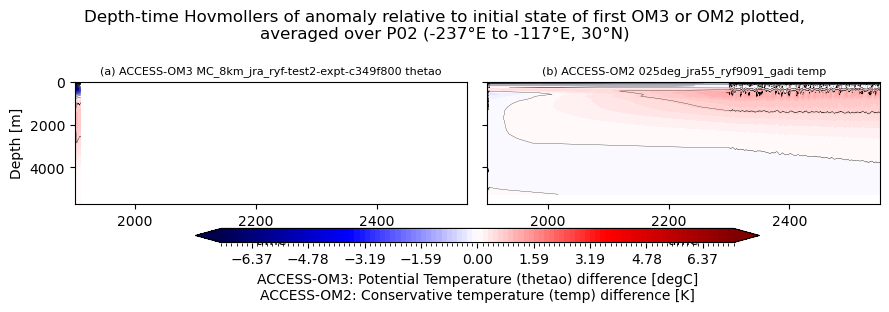

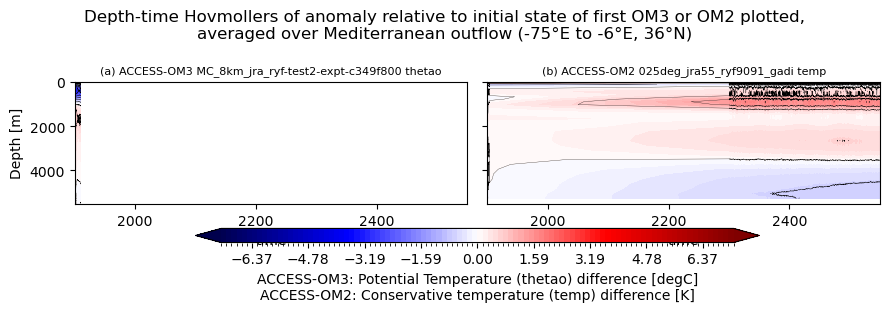

In [19]:
doplots(om3variable = "thetao",
        om2variable = "temp",
        mkmdfig=False)

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/mkmd/temp-salt-vs-depth-time_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/mkmd/temp-salt-vs-depth-time.md


Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/mkmd/temp-salt-vs-depth-time.md successfully.


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/mkmd/temp-salt-vs-depth-time_02.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/mkmd/temp-salt-vs-depth-time.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/mkmd/temp-salt-vs-depth-time.md successfully.


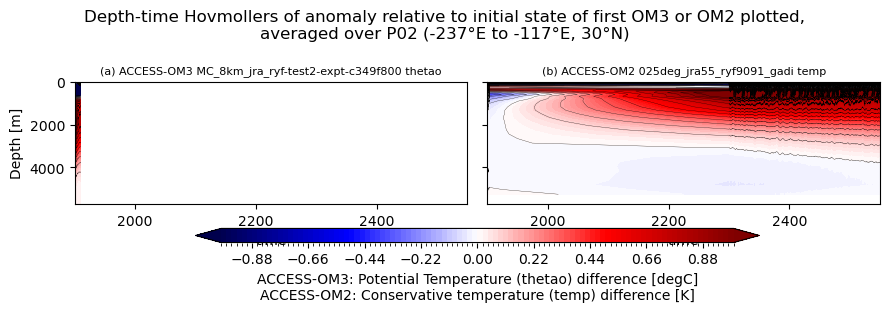

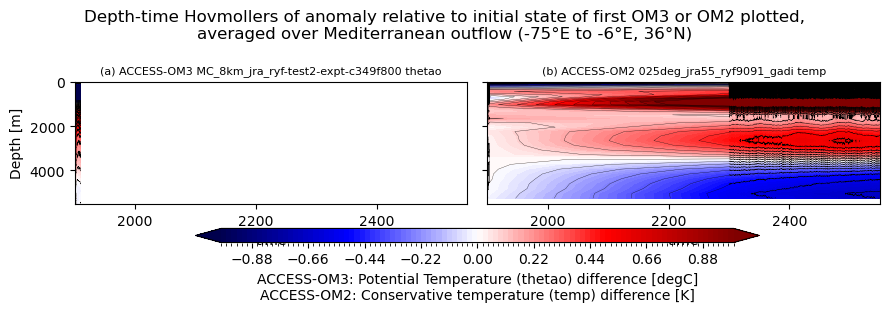

In [20]:
doplots(om3variable = "thetao",
        om2variable = "temp",
        vmax = 1)

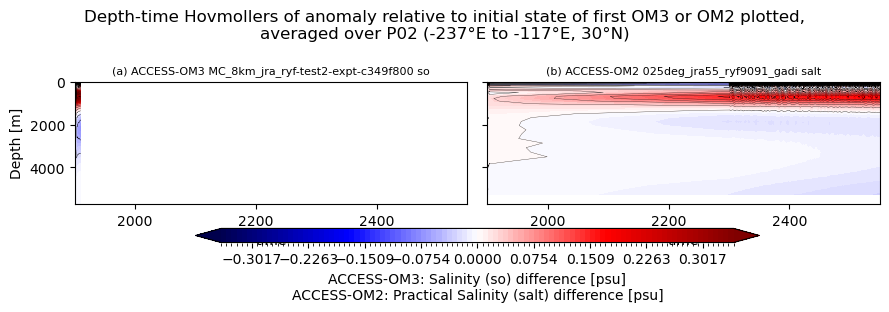

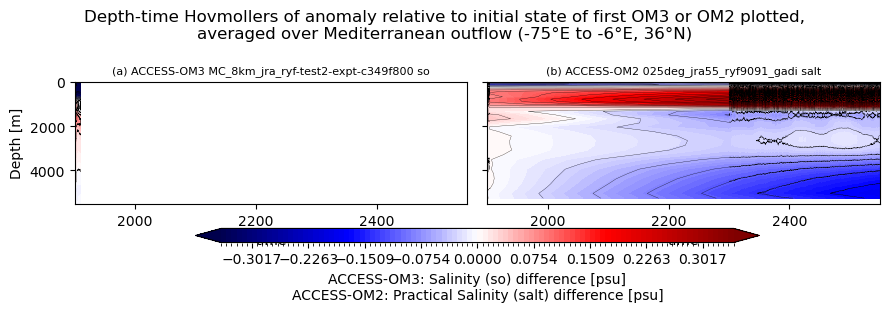

In [21]:
doplots(om3variable = "so",
        om2variable = "salt",
        mkmdfig=False)

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/mkmd/temp-salt-vs-depth-time_03.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/mkmd/temp-salt-vs-depth-time.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/mkmd/temp-salt-vs-depth-time.md successfully.


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/mkmd/temp-salt-vs-depth-time_04.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/mkmd/temp-salt-vs-depth-time.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/mkmd/temp-salt-vs-depth-time.md successfully.


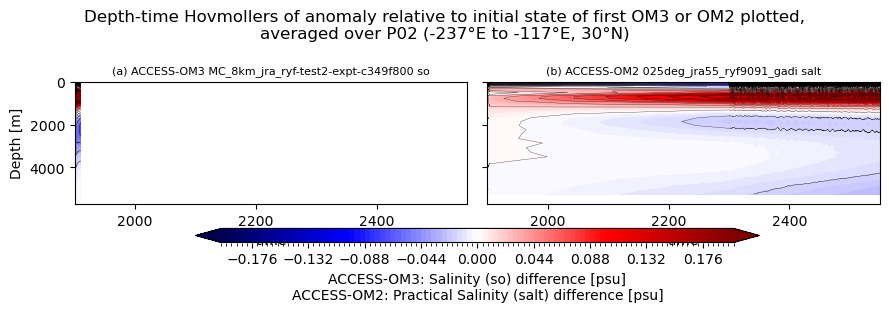

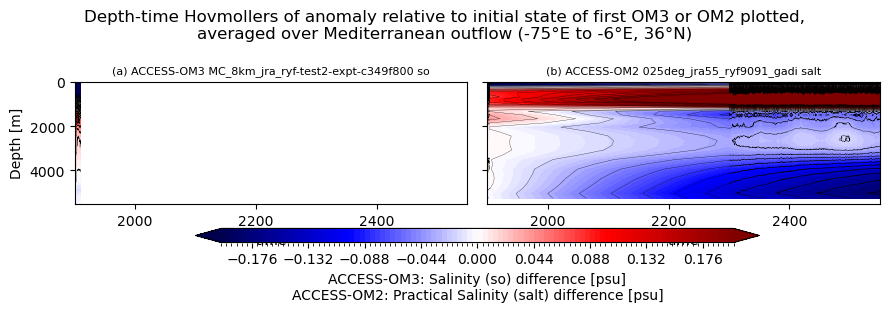

In [22]:
doplots(om3variable = "so",
        om2variable = "salt",
        vmax = 0.2)

In [23]:
client.close()